# Evaluation of Fuzzy Method / Model

This notebook evaluates Sillage's **Mamdani fuzzy recommendation model** using seven synthetic traveler scenarios and the **50 European destinations** in `european_city_destination_dataset_prototype.csv`. It retains the original 19 questionnaire themes and 27 fuzzy IF–THEN rules.

The destination values are explicitly marked `SYNTHETIC_PLACEHOLDER`. Results demonstrate **technical behavior under assumptions**, not real-world destination quality. We distinguish PASS, FAIL and INCONCLUSIVE.


## Data

**Scenario inputs.** The seven profiles below contain 16 Personality Test answers and 12 Trip Questionnaire answers each. The latter three scenarios vary selected answers while holding the remaining inputs constant.

**Destination data.** The accompanying `european_city_destination_dataset_prototype.csv` contains 50 European destinations and named attributes measured on [0,1], categorical landscape/climate flags, and `daily_cost_eur_estimate`. It does **not** contain the former `t1`–`t27` columns or 1–9 scores. A transparent mapping below adapts it to the questionnaire themes. Some themes remain unmeasurable (not silently guessed).


**Expected behavior.** Adventurous, relaxing and gastronomy-focused travelers should be compatible with destinations offering the corresponding attributes. Targeted test pairs isolate changes in trip pace, physical activity and budget. These are hypotheses to test, not conclusions.

### Data Preprocessing

Questionnaire answers are normalized to [0,1] according to their scales. The European destination scores **already lie on [0,1]** and must not be re-normalized as 1–9 ratings. Climate and landscape selections use the supplied binary flags. Budget screening uses only an **illustrative trip-cost proxy** based on the synthetic daily EUR cost, an assumed seven-day trip, and a manually specified illustrative EUR→CHF factor; this is not a real quote.


The model is assessed using synthetic scenarios, pairwise input perturbations, output bounds, repeatability and data coverage. No user study is included in this technical-validation stage.

### Load destination data

In [2]:
#%pip install numpy pandas

In [3]:
import numpy as np
import pandas as pd

DATA_FILE = "european_city_destination_dataset_prototype.csv"
cities = pd.read_csv(DATA_FILE).rename(columns={"city": "City"})
assert cities["City"].is_unique
assert len(cities) == 50, f"Unexpected destination count: {len(cities)}"

# Exactly the 19 themes having at least one question.
selected_themes = [1,2,3,4,6,7,8,12,13,14,17,18,19,20,21,22,23,24,27]
selected_columns = [f"t{t}" for t in selected_themes]

# A mapping, NOT a claim that all questionnaire themes are directly observed.
# t1 (change of scenery) depends on the user's home location; the dataset cannot encode it.
# t3 (choice of local-life vs tourist activities) cannot be inferred from one authenticity score.
# t18 is evaluated with trip-cost proxy rather than a quality score.
# t27 shared experience TYPES are not recorded; the generic score is insufficient.
THEME_TO_ATTRIBUTE = {
    "t1": None, "t2": "gastronomy", "t3": None,
    "t4": "relaxation_opportunities", "t6": "must_see_landmarks",
    "t7": "infrastructure_quality", "t8": "water_hygiene_conditions",
    "t12": "unique_experiences", "t13": "landscape_quality",
    "t14": "travel_pace_variety", "t17": "spontaneity_friendliness",
    "t18": None, "t19": "safety", "t20": "healthcare_accessibility",
    "t21": "accommodation_comfort_range", "t22": None,
    "t23": "transport_accessibility", "t24": "adventure_sports_opportunities",
    "t27": None,
}

for theme, field in THEME_TO_ATTRIBUTE.items():
    cities[theme] = pd.to_numeric(cities[field], errors="coerce") if field else np.nan

cities_selected = cities[["City"] + selected_columns].copy()
measured = [t for t in selected_columns if THEME_TO_ATTRIBUTE[t] is not None]
assert cities[measured].apply(lambda col: col.dropna().between(0, 1).all()).all()
assert cities["data_status"].eq("SYNTHETIC_PLACEHOLDER").all()
print("Destinations:", len(cities_selected))
print("Questionnaire themes:", len(selected_columns))
print("Direct numeric theme attributes:", len(measured))
print("Unmapped numeric themes:", [t for t in selected_columns if t not in measured])
display(cities_selected.head())


Destinations: 50
Questionnaire themes: 19
Direct numeric theme attributes: 14
Unmapped numeric themes: ['t1', 't3', 't18', 't22', 't27']


,City,t1,t2,t3,t4,t6,t7,t8,t12,t13,t14,t17,t18,t19,t20,t21,t22,t23,t24,t27
0,Vienna,NaN,0.90,NaN,0.49,0.95,0.98,0.81,0.83,0.52,0.46,0.84,NaN,0.80,0.91,0.95,NaN,0.80,0.84,NaN
1,Salzburg,NaN,0.82,NaN,0.75,0.85,0.80,0.92,0.49,0.95,0.76,0.63,NaN,0.93,0.81,0.76,NaN,0.71,0.89,NaN
2,Brussels,NaN,0.90,NaN,0.40,0.82,0.78,0.83,0.79,0.50,0.79,0.76,NaN,0.88,0.72,0.56,NaN,0.79,0.41,NaN
3,Bruges,NaN,0.78,NaN,0.85,0.90,0.67,0.74,0.51,0.51,0.47,0.54,NaN,0.73,0.87,0.72,NaN,0.88,0.29,NaN
4,Dubrovnik,NaN,0.78,NaN,0.42,0.90,0.74,0.88,0.70,0.38,0.50,0.91,NaN,0.73,0.80,0.91,NaN,0.90,0.74,NaN


## 2. questionnaire input types

In [4]:

# Questionnaire input types for each selected theme

question_types = {
    "t1":  {"P": None, "T": "scale_7"},
    "t2":  {"P": "slider_100", "T": None},
    "t3":  {"P": "categorical", "T": None},
    "t4":  {"P": "slider_100", "T": "slider_100"},
    "t6":  {"P": None, "T": "scale_7"},
    "t7":  {"P": "scale_7", "T": None},
    "t8":  {"P": "scale_7", "T": None},
    "t12": {"P": "slider_100", "T": "scale_7"},
    "t13": {"P": "slider_100", "T": "multiple_choice"},
    "t14": {"P": "scale_7", "T": "scale_7"},
    "t17": {"P": "scale_7", "T": None},
    "t18": {"P": "scale_7", "T": "budget"},
    "t19": {"P": "scale_7", "T": None},
    "t20": {"P": "scale_7", "T": None},
    "t21": {"P": "scale_7", "T": "scale_5"},
    "t22": {"P": "categorical", "T": "categorical"},
    "t23": {"P": "scale_7", "T": "multiple_choice"},
    "t24": {"P": "scale_7", "T": "scale_5"},
    "t27": {"P": None, "T": "multiple_choice"}
}

# Check if all selected themes are represented
assert set(question_types) == set(selected_columns)

print("Number of themes:", len(question_types))

print(
    "Personality questions:",
    sum(q["P"] is not None for q in question_types.values())
)

print(
    "Trip questions:",
    sum(q["T"] is not None for q in question_types.values())
)


Number of themes: 19
Personality questions: 16
Trip questions: 12


### 3. Reference answer

In [5]:

from copy import deepcopy

# Default Personality Test answers
base_personality = {
    "t2": 50,                  # Gastronomy (0-100)
    "t3": "Combination",      # Authenticity
    "t4": 50,                  # Relaxation (0-100%)
    "t7": 4,                   # Infrastructure (1-7)
    "t8": 4,                   # Hygiene precautions (1-7)
    "t12": 50,                 # Unique experiences (0-100)
    "t13": 50,                 # Natural landscapes (0-100)
    "t14": 4,                  # Travel pace (1-7)
    "t17": 4,                  # Flexibility (1-7)
    "t18": 4,                  # Price sensitivity (1-7)
    "t19": 6,                  # Personal safety (1-7)
    "t20": 6,                  # Healthcare (1-7)
    "t21": 4,                  # Accommodation comfort (1-7)
    "t22": "Mild",             # Climate preference
    "t23": 4,                  # Transport effort tolerance (1-7)
    "t24": 4                   # Physical activity (1-7)
}

# Default Trip Questionnaire answers
base_trip = {
    "t1": 4,                   # Change of scenery (1-7)
    "t4": 50,                  # Relaxation (0-100%)
    "t6": 4,                   # Landmarks (1-7)
    "t12": 4,                  # Unique experiences (1-7)
    "t13": ["Mountains", "Beaches"],
    "t14": 4,                  # Travel pace (1-7)
    "t18": {
        "preferred": 1800,
        "maximum": 2500
    },                        # Budget in CHF
    "t21": 3,                  # Accommodation comfort (1-5)
    "t22": "Mild",             # Climate
    "t23": ["Walking", "Public transport"],
    "t24": 3,                  # Physical activity (1-5)
    "t27": ["Quality time"]
}


### 4. Initialize four profiles


Here we created four snthetic taveler profiles to evaluate our fuzzy recommendation system.
- Adventure lover
- Relaxation lover
- Food Explorer
- Balanced Traveler

Each traveler answers the questions from the personality test and trip questionnaire.
We use 19 themes. The goal is to check whether our system produces logical and consistent destination recommendations for different traveler preferences.

In [6]:

# Initialize the four scenarios
scenario_names = [
    "Adventure Lover",
    "Relaxation Lover",
    "Food Explorer",
    "Balanced Traveler"
]

personality_answers = {
    name: deepcopy(base_personality)
    for name in scenario_names
}

trip_answers = {
    name: deepcopy(base_trip)
    for name in scenario_names
}

# Scenario 1: Adventure Lover
personality_answers["Adventure Lover"].update({
    "t2": 35,
    "t3": "Local life",
    "t4": 15,
    "t7": 6,
    "t12": 90,
    "t13": 90,
    "t14": 7,
    "t17": 6,
    "t21": 3,
    "t22": "Cool",
    "t23": 6,
    "t24": 7
})

trip_answers["Adventure Lover"].update({
    "t1": 7,
    "t4": 10,
    "t6": 3,
    "t12": 7,
    "t13": ["Mountains", "Forests"],
    "t14": 7,
    "t18": {"preferred": 1600, "maximum": 2200},
    "t21": 2,
    "t22": "Mild",
    "t23": ["Walking", "Bicycle"],
    "t24": 5,
    "t27": ["Group activities"]
})

# Scenario 2: Relaxation Lover
personality_answers["Relaxation Lover"].update({
    "t2": 40,
    "t4": 85,
    "t7": 2,
    "t8": 2,
    "t12": 25,
    "t13": 80,
    "t14": 1,
    "t17": 2,
    "t21": 7,
    "t22": "Warm",
    "t23": 2,
    "t24": 1
})

trip_answers["Relaxation Lover"].update({
    "t1": 3,
    "t4": 90,
    "t6": 2,
    "t12": 2,
    "t13": ["Beaches", "Lakes"],
    "t14": 1,
    "t18": {"preferred": 2000, "maximum": 3000},
    "t21": 5,
    "t22": "Warm",
    "t23": ["Car", "Public transport"],
    "t24": 1,
    "t27": ["Quality time"]
})

# Scenario 3: Food Explorer
personality_answers["Food Explorer"].update({
    "t2": 95,
    "t3": "Local life",
    "t4": 35,
    "t12": 75,
    "t13": 45,
    "t14": 5,
    "t17": 5,
    "t18": 5,
    "t22": "Warm",
    "t24": 3
})

trip_answers["Food Explorer"].update({
    "t1": 6,
    "t4": 30,
    "t6": 6,
    "t12": 6,
    "t13": ["Countryside"],
    "t14": 5,
    "t18": {"preferred": 2200, "maximum": 3000},
    "t22": "Warm",
    "t23": ["Walking", "Public transport"],
    "t24": 2,
    "t27": ["Meeting new people", "Quality time"]
})

print("Synthetic profiles created successfully!")
print("Number of scenarios:", len(scenario_names))


Synthetic profiles created successfully!
Number of scenarios: 4


### 5. Additional test scenarios


To further evaluate the fuzzy recommendation system, we added three scenarios:

- **Adventurer Seeking Relaxation:** A traveler who usually enjoys adventure but wants a relaxing vacation this time.
- **Budget-Constrained Traveler:** A traveler with a limited maximum budget.
- **Adventure Preference Change:** A traveler whose desired adventure level changes while all other preferences remain the same.

These scenarios help us test whether the system adapts to changing trip preferences, respects budget constraints, and behaves consistently when a single input is modified.


In [7]:

from copy import deepcopy

# Scenario 5: Adventurer Seeking Relaxation
name = "Adventurer Seeking Relaxation"

personality_answers[name] = deepcopy(
    personality_answers["Adventure Lover"]
)

trip_answers[name] = deepcopy(
    trip_answers["Adventure Lover"]
)

# only change current trip preferences
trip_answers[name].update({
    "t4": 90,     # High relaxation
    "t14": 1,     # Very relaxed travel pace
    "t24": 1      # Very low physical activity
})


# Scenario 6: Budget-Constrained Traveler
name = "Budget-Constrained Traveler"

personality_answers[name] = deepcopy(
    personality_answers["Balanced Traveler"]
)

trip_answers[name] = deepcopy(
    trip_answers["Balanced Traveler"]
)

# only change the budget
trip_answers[name]["t18"] = {
    "preferred": 500,
    "maximum": 700
}


# Scenario 7: Adventure Preference Change
name = "Adventure Preference Change"

personality_answers[name] = deepcopy(
    personality_answers["Adventure Lover"]
)

trip_answers[name] = deepcopy(
    trip_answers["Adventure Lover"]
)

# Here we change only one variable
trip_answers[name]["t24"] = 1


# Update the list of scenarios
scenario_names = [
    "Adventure Lover",
    "Relaxation Lover",
    "Food Explorer",
    "Balanced Traveler",
    "Adventurer Seeking Relaxation",
    "Budget-Constrained Traveler",
    "Adventure Preference Change"
]

print("Total number of scenarios:", len(scenario_names))


Total number of scenarios: 7


In [8]:
# Expected themes from the questionnaires
expected_p = {
    theme for theme, q in question_types.items()
    if q["P"] is not None
}

expected_t = {
    theme for theme, q in question_types.items()
    if q["T"] is not None
}


# Verify the seven scenarios
assert len(scenario_names) == 7

for name in scenario_names:
    assert set(personality_answers[name]) == expected_p
    assert set(trip_answers[name]) == expected_t

# Scenario 5: Same personality, different trip
assert (
    personality_answers["Adventure Lover"]
    == personality_answers["Adventurer Seeking Relaxation"]
)

# Scenario 6: Only the budget changes
budget_test = deepcopy(
    trip_answers["Budget-Constrained Traveler"]
)
budget_test["t18"] = deepcopy(
    trip_answers["Balanced Traveler"]["t18"]
)

assert budget_test == trip_answers["Balanced Traveler"]

# Scenario 7: Only the adventure preference changes
adventure_test = deepcopy(
    trip_answers["Adventure Preference Change"]
)
adventure_test["t24"] = trip_answers[
    "Adventure Lover"
]["t24"]

assert adventure_test == trip_answers["Adventure Lover"]

print("All seven scenarios are correctly configured!")


All seven scenarios are correctly configured!


### 6. Display Answers


In [9]:
# Then we check all scenarios
for name in scenario_names:
    p = personality_answers[name]
    t = trip_answers[name]

    assert set(p) == expected_p, (
        f"Personality questions mismatch: {name}"
    )
    assert set(t) == expected_t, (
        f"Trip questions mismatch: {name}"
    )

    assert t["t18"]["preferred"] <= t["t18"]["maximum"]

    print(
        f"{name}: "
        f"{len(p)} personality answers, "
        f"{len(t)} trip answers"
    )


Adventure Lover: 16 personality answers, 12 trip answers
Relaxation Lover: 16 personality answers, 12 trip answers
Food Explorer: 16 personality answers, 12 trip answers
Balanced Traveler: 16 personality answers, 12 trip answers
Adventurer Seeking Relaxation: 16 personality answers, 12 trip answers
Budget-Constrained Traveler: 16 personality answers, 12 trip answers
Adventure Preference Change: 16 personality answers, 12 trip answers


In [10]:
# Display for Personality Test responses
personality_df = pd.DataFrame.from_dict(
    personality_answers,
    orient="index"
)

display(personality_df)

# Display for Trip Questionnaire responses
trip_df = pd.DataFrame.from_dict(
    trip_answers,
    orient="index"
)

display(trip_df)


,t2,t3,t4,t7,t8,t12,t13,t14,t17,t18,t19,t20,t21,t22,t23,t24
Adventure Lover,35,Local life,15,6,4,90,90,7,6,4,6,6,3,Cool,6,7
Relaxation Lover,40,Combination,85,2,2,25,80,1,2,4,6,6,7,Warm,2,1
Food Explorer,95,Local life,35,4,4,75,45,5,5,5,6,6,4,Warm,4,3
Balanced Traveler,50,Combination,50,4,4,50,50,4,4,4,6,6,4,Mild,4,4
Adventurer Seeking Relaxation,35,Local life,15,6,4,90,90,7,6,4,6,6,3,Cool,6,7
Budget-Constrained Traveler,50,Combination,50,4,4,50,50,4,4,4,6,6,4,Mild,4,4
Adventure Preference Change,35,Local life,15,6,4,90,90,7,6,4,6,6,3,Cool,6,7


,t1,t4,t6,t12,t13,t14,t18,t21,t22,t23,t24,t27
Adventure Lover,7,10,3,7,"[Mountains, Forests]",7,"{'preferred': 1600, 'maximum': 2200}",2,Mild,"[Walking, Bicycle]",5,[Group activities]
Relaxation Lover,3,90,2,2,"[Beaches, Lakes]",1,"{'preferred': 2000, 'maximum': 3000}",5,Warm,"[Car, Public transport]",1,[Quality time]
Food Explorer,6,30,6,6,[Countryside],5,"{'preferred': 2200, 'maximum': 3000}",3,Warm,"[Walking, Public transport]",2,"[Meeting new people, Quality time]"
Balanced Traveler,4,50,4,4,"[Mountains, Beaches]",4,"{'preferred': 1800, 'maximum': 2500}",3,Mild,"[Walking, Public transport]",3,[Quality time]
Adventurer Seeking Relaxation,7,90,3,7,"[Mountains, Forests]",1,"{'preferred': 1600, 'maximum': 2200}",2,Mild,"[Walking, Bicycle]",1,[Group activities]
Budget-Constrained Traveler,4,50,4,4,"[Mountains, Beaches]",4,"{'preferred': 500, 'maximum': 700}",3,Mild,"[Walking, Public transport]",3,[Quality time]
Adventure Preference Change,7,10,3,7,"[Mountains, Forests]",7,"{'preferred': 1600, 'maximum': 2200}",2,Mild,"[Walking, Bicycle]",1,[Group activities]


# Fuzzy Model — using the class tutorials

This section follows the class **Fuzzy Control System** and **Fuzzy Vacation Planner** tutorials: fuzzy variables → membership functions → IF–THEN rules → Mamdani inference → centroid defuzzification.

**Important methodological distinction:** the questionnaire answers represent **preferred levels**, **importance/interest**, **tolerance**, **categorical preferences**, or **budget constraints**. They must not be interpreted as interchangeable scores. Every theme has a dedicated semantic treatment below.

## 1. Imports and model configuration


In [11]:
# If necessary, run once in your active Jupyter environment:
# %pip install numpy pandas matplotlib scikit-fuzzy
import ast
import json
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

THEME_NAMES = {
    't1':'Change of Scenery', 't2':'Food / Gastronomy', 't3':'Authenticity',
    't4':'Relaxation', 't6':'Must-see Landmarks', 't7':'Infrastructure',
    't8':'Drinking Water / Hygiene', 't12':'Unique Experiences',
    't13':'Beautiful Landscapes', 't14':'Travel Pace', 't17':'Flexibility',
    't18':'Budget & Pricing', 't19':'Personal Safety', 't20':'Healthcare',
    't21':'Comfort & Accommodation', 't22':'Climate & Weather',
    't23':'Transportation & Accessibility', 't24':'Adventure & Sports',
    't27':'Relationships & Shared Experiences'
}
# These groups are a transparent DESIGN choice, not an established taxonomy.
THEME_GROUPS = {
    'experiences': ['t1','t2','t3','t6','t12','t13','t24','t27'],
    'comfort': ['t4','t8','t14','t19','t20','t21','t22'],
    'practical': ['t7','t17','t18','t23']
}
THEME_KIND = {
    't1':'level', 't2':'interest_benefit', 't3':'category',
    't4':'level', 't6':'importance_benefit', 't7':'tolerance',
    't8':'tolerance', 't12':'interest_importance',
    't13':'importance_plus_categories', 't14':'level',
    't17':'level', 't18':'budget', 't19':'importance_benefit',
    't20':'importance_benefit', 't21':'level',
    't22':'category', 't23':'tolerance_plus_categories',
    't24':'level', 't27':'category'
}
assert set(THEME_NAMES) == set(question_types) == set(selected_columns)
assert set(THEME_KIND) == set(THEME_NAMES)
assert set(t for group in THEME_GROUPS.values() for t in group) == set(THEME_NAMES)
assert sum(map(len, THEME_GROUPS.values())) == 19

# Assumptions for subsequent sensitivity testing, not empirically established parameters.
P_WEIGHT, T_WEIGHT = 0.30, 0.70
WEIGHT_FLOOR = 0.15
LEVEL_WIDTH = 0.65
COVERAGE_REQUIRED = 19  # Completeness target, not a requirement for producing a provisional score.

print('Configured themes:', len(THEME_KIND))
print(pd.DataFrame([{'theme': t, 'name': THEME_NAMES[t], 'meaning': THEME_KIND[t],
                     'P type': question_types[t]['P'], 'T type': question_types[t]['T']}
                    for t in selected_columns]).to_string(index=False))

Configured themes: 19
theme                               name                    meaning      P type          T type
   t1                  Change of Scenery                      level        None         scale_7
   t2                  Food / Gastronomy           interest_benefit  slider_100            None
   t3                       Authenticity                   category categorical            None
   t4                         Relaxation                      level  slider_100      slider_100
   t6                 Must-see Landmarks         importance_benefit        None         scale_7
   t7                     Infrastructure                  tolerance     scale_7            None
   t8           Drinking Water / Hygiene                  tolerance     scale_7            None
  t12                 Unique Experiences        interest_importance  slider_100         scale_7
  t13               Beautiful Landscapes importance_plus_categories  slider_100 multiple_choice
  t14             

## 2. Crisp answers and thematic compatibility

- **Level:** compare the requested level with the destination's offered level (P/T fusion applies only when both questions measure a similar level).
- **Interest/importance:** the answer affects the **weight**, not a target level. A better destination feature remains preferable.
- **Tolerance:** a traveler tolerant of weak infrastructure/hygiene is penalized **less** for weak provision; strong provision is never penalized.
- **Categories:** compare category labels directly. A category is never assigned an arbitrary ordinal number. `No preference` means this response does not discriminate.
- **Budget:** compare a **documented, comparable** trip total in CHF with the hard maximum, rather than the legacy ordinal `t18` score.

The normalized closeness and tolerance curves below are **model assumptions**, not calibrated empirical tourism laws. A missing observation is `NaN`, not zero or an invented proxy. Original city scores are only temporary indicators pending documentation.


In [12]:
def normalized_answer(value, answer_type):
    if value is None or answer_type not in ('slider_100','scale_7','scale_5'):
        return np.nan
    bounds = {'slider_100':(0.,100.), 'scale_7':(1.,7.), 'scale_5':(1.,5.)}
    try:
        x = float(value)
    except (ValueError, TypeError):
        return np.nan
    lo, hi = bounds[answer_type]
    if not np.isfinite(x) or not lo <= x <= hi:
        raise ValueError(f'Unexpected value {value!r} for {answer_type}')
    return (x-lo)/(hi-lo)


def city_quality(row, theme):
    """Use directly mapped European attributes on [0,1], with no 1-9 rescaling."""
    x = pd.to_numeric(row.get(theme, np.nan), errors='coerce')
    return float(x) if pd.notna(x) and np.isfinite(x) and 0 <= x <= 1 else np.nan


def categories(value):
    if value is None or (isinstance(value,float) and np.isnan(value)):
        return set()
    if isinstance(value,(list,tuple,set)):
        return {str(v).strip().casefold() for v in value if str(v).strip()}
    if not isinstance(value,str):
        return set()
    value = value.strip()
    if not value:
        return set()
    if value.startswith('['):
        for parse in (json.loads, ast.literal_eval):
            try:
                parsed=parse(value)
                if isinstance(parsed,(list,tuple,set)):
                    return categories(parsed)
            except (ValueError,TypeError,SyntaxError,json.JSONDecodeError):
                pass
    sep='|' if '|' in value else ';' if ';' in value else None
    return {v.strip().casefold() for v in (value.split(sep) if sep else [value]) if v.strip()}


def city_categories(row, theme):
    """Extract categorical facts only where corresponding CSV flags exist."""
    prefix = {"t13": "landscape_", "t22": "climate_"}.get(theme)
    if prefix is None:
        return set()  # Do not infer types of activities, authenticity or transport modes.
    options = (['mountains','beaches','forests','lakes','countryside','desert','other']
               if theme == 't13' else ['cold','cool','mild','warm','hot'])
    return {label for label in options
            if pd.to_numeric(row.get(prefix + label), errors='coerce') == 1}


def categorical_compatibility(preference, offered):
    """Exact label overlap (crisp set matching); resulting score feeds fuzzy inference."""
    requested,available=categories(preference),categories(offered)
    if not requested or requested == {'no preference'}:
        return np.nan  # no stated preference; do not invent a discriminating score
    if not available:
        return np.nan
    return len(requested & available)/len(requested)


def level_compatibility(desired, offered):
    if pd.isna(desired) or pd.isna(offered):
        return np.nan
    return float(np.clip(1.0-abs(desired-offered)/LEVEL_WIDTH, 0, 1))


def tolerance_compatibility(tolerance, provision):
    if pd.isna(tolerance) or pd.isna(provision):
        return np.nan
    # Provision=1 always satisfies traveler; higher tolerance softens low-provision penalty.
    return float(np.clip(1.0-(1.0-provision)*(1.0-tolerance),0,1))


def weighted_available(pairs):
    valid=[(float(v),float(w)) for v,w in pairs if pd.notna(v) and np.isfinite(v) and w > 0]
    return float(sum(v*w for v,w in valid)/sum(w for _,w in valid)) if valid else np.nan


def importance_weight(value, answer_type):
    v=normalized_answer(value,answer_type)
    return float(WEIGHT_FLOOR+(1-WEIGHT_FLOOR)*v) if pd.notna(v) else 1.0


def combination_weight(p, ptype, t, ttype):
    """Combine only answers that measure criterion importance or interest."""
    weights=[]
    if ptype is not None:
        weights.append((importance_weight(p,ptype),P_WEIGHT))
    if ttype is not None:
        weights.append((importance_weight(t,ttype),T_WEIGHT))
    return weighted_available(weights) if weights else 1.0


# EXPLICIT SIMULATION ASSUMPTIONS: not verified travel facts or current exchange rates.
TRIP_DAYS = 7
EUR_TO_CHF_ILLUSTRATIVE = 1.0
# Assumes daily_cost_eur_estimate is a per-person daily proxy and one traveler.
# The actual trip questionnaire does not provide duration/party size here.

def estimated_trip_cost_chf(row):
    daily = pd.to_numeric(row.get('daily_cost_eur_estimate', np.nan), errors='coerce')
    if pd.isna(daily) or not np.isfinite(daily) or daily < 0:
        return np.nan
    return float(daily * TRIP_DAYS * EUR_TO_CHF_ILLUSTRATIVE)


def budget_compatibility(budget, row):
    """Budget screening using a clearly labeled synthetic, assumed trip-cost proxy."""
    if not isinstance(budget, dict):
        return np.nan, 'unknown'
    cost = estimated_trip_cost_chf(row)
    try:
        max_cost, pref = float(budget['maximum']), float(budget['preferred'])
    except (ValueError, KeyError, TypeError):
        return np.nan, 'unknown'
    if not np.isfinite(cost) or not np.isfinite(max_cost) or not np.isfinite(pref) or max_cost <= 0:
        return np.nan, 'unknown'
    if cost > max_cost:
        return 0.0, 'excluded'
    if cost <= pref or pref >= max_cost:
        return 1.0, 'eligible'
    return float(np.clip((max_cost - cost) / (max_cost - pref), 0, 1)), 'eligible'


def theme_compatibility(theme, personality, trip, city):
    """19-theme semantic mapping. Returns compatibility, weight, and audit status."""
    kind=THEME_KIND[theme]
    p,t=personality.get(theme),trip.get(theme)
    ptype,ttype=question_types[theme]['P'],question_types[theme]['T']
    supply=city_quality(city,theme)
    pn,tn=normalized_answer(p,ptype),normalized_answer(t,ttype)
    if kind == 'budget':
        score,state=budget_compatibility(t,city)
        return score,importance_weight(p,ptype),'budget:'+state
    if kind == 'category':
        offered=city_categories(city,theme)
        pscore=categorical_compatibility(p,offered)
        tscore=categorical_compatibility(t,offered)
        # 'No preference' must not inadvertently dilute the specified preference.
        score=weighted_available([(pscore,P_WEIGHT),(tscore,T_WEIGHT)])
        return score,1.0,('category' if pd.notna(score) else 'missing_or_unspecified_category')
    if kind == 'level' and theme == 't14':
        return supply, 1.0, ('partial_pace_variety_only' if pd.notna(supply) else 'missing_pace')
    if kind == 'level':
        score=weighted_available([(level_compatibility(pn,supply),P_WEIGHT),
                                  (level_compatibility(tn,supply),T_WEIGHT)])
        return score,1.0,('level' if pd.notna(score) else 'missing_level')
    if kind == 'tolerance':
        score=tolerance_compatibility(pn,supply)
        return score,1.0,('tolerance' if pd.notna(score) else 'missing_tolerance')
    if kind in ('interest_benefit','importance_benefit','interest_importance'):
        weight=combination_weight(p,ptype,t,ttype)
        return supply,weight,('importance_weighted_benefit' if pd.notna(supply) else 'missing_benefit')
    if kind == 'importance_plus_categories':
        # P: importance of nature; T: types of landscapes. Both must NOT be averaged
        # as though they measured the same thing.
        match=categorical_compatibility(t,city_categories(city,theme))
        if pd.notna(match):
            return match,importance_weight(p,ptype),'category_weighted_by_P_importance'
        # Missing categories: a numeric landscape availability score is only partial
        # evidence; explicitly mark it as NOT fulfilling the trip category requirement.
        return supply,importance_weight(p,ptype),('partial_P_only_missing_T_categories'
                                                   if pd.notna(supply) else 'missing_categories')
    if kind == 'tolerance_plus_categories':
        # P: tolerance of difficult mobility, T: preferred transport modes.
        pscore=tolerance_compatibility(pn,supply)
        tscore=categorical_compatibility(t,city_categories(city,theme))
        combined=weighted_available([(pscore,P_WEIGHT),(tscore,T_WEIGHT)])
        status=('complete_transport' if pd.notna(pscore) and pd.notna(tscore)
                else 'partial_transport' if pd.notna(combined) else 'missing_transport')
        return combined,1.0,status
    raise KeyError(theme)


def compare_traveler_destination(scenario_name, city):
    person,trip=personality_answers[scenario_name],trip_answers[scenario_name]
    return {theme:dict(zip(('compatibility','weight','status'),
                            theme_compatibility(theme,person,trip,city)))
            for theme in selected_columns}

assert len(compare_traveler_destination(scenario_names[0],cities.iloc[0].to_dict()))==19
assert tolerance_compatibility(0.9,0.2) > tolerance_compatibility(0.1,0.2)
assert tolerance_compatibility(0.9,1) == tolerance_compatibility(0.1,1) == 1
assert categories(['Mountains','Lakes']) == {'mountains','lakes'}
assert pd.isna(categorical_compatibility('No preference',{'warm'}))
print('All 19 themes mapped according to questionnaire meaning.')

All 19 themes mapped according to questionnaire meaning.


## 3. Fuzzy variables and membership functions (as in class)

We feed three aggregated, **observed** compatibilities to the Mamdani controller. The `low`, `medium`, and `high` triangular membership functions and the 0–100 output are **prototype settings** requiring sensitivity analysis. Partial coverage is shown separately rather than being silently treated as perfect compatibility.

c:\Users\schre\Documents\Master\semestre3\FuzzySets\fuzzy-tutorial-main\fuzzy-tutorial-main\venv\lib\site-packages\skfuzzy\control\fuzzyvariable.py:122: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


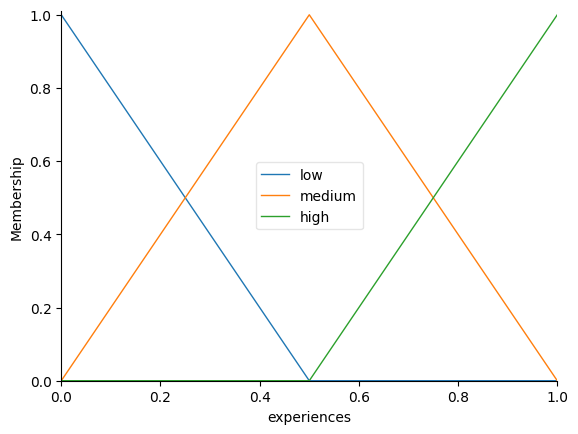

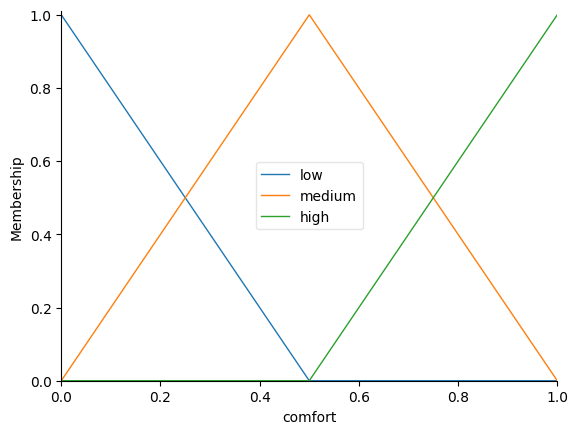

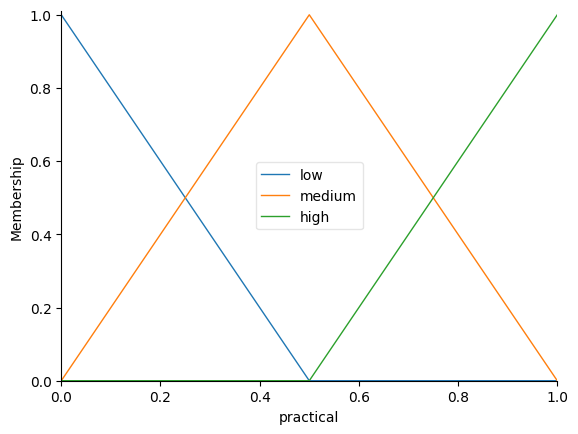

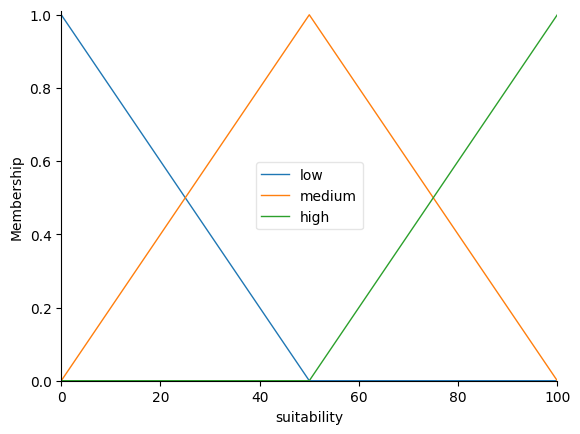

In [13]:
compatibility_universe = np.arange(0,1.001,0.01)
suitability_universe = np.arange(0,100.01,0.5)
experiences = ctrl.Antecedent(compatibility_universe,'experiences')
comfort = ctrl.Antecedent(compatibility_universe,'comfort')
practical = ctrl.Antecedent(compatibility_universe,'practical')
suitability = ctrl.Consequent(suitability_universe,'suitability')
suitability.defuzzify_method='centroid'
for var in (experiences,comfort,practical):
    var['low'] = fuzz.trimf(var.universe,[0,0,0.5])
    var['medium'] = fuzz.trimf(var.universe,[0,0.5,1])
    var['high'] = fuzz.trimf(var.universe,[0.5,1,1])
suitability['low'] = fuzz.trimf(suitability.universe,[0,0,50])
suitability['medium'] = fuzz.trimf(suitability.universe,[0,50,100])
suitability['high'] = fuzz.trimf(suitability.universe,[50,100,100])

# Classroom visualizations
experiences.view()
comfort.view()
practical.view()
suitability.view()
plt.show()

## 4. Fuzzy IF–THEN rules

The rules are constructed using `ctrl.Rule`, exactly as in the classroom examples. The 27-rule grid ensures coverage across every combination of *low/medium/high* for the three group inputs. **The consequent policy is an explicit modeling hypothesis**; it is not copied from an empirically validated tourism rule base. In particular, a low practical score prevents a high output category.

In [14]:
# Two rules written explicitly, in the course style.
rule_all_high=ctrl.Rule(experiences['high'] & comfort['high'] & practical['high'],
                        suitability['high'],label='all_high')
rule_all_low=ctrl.Rule(experiences['low'] & comfort['low'] & practical['low'],
                       suitability['low'],label='all_low')

levels=('low','medium','high')
rule_list=[rule_all_high,rule_all_low]
rule_table=[]
for e,c,p in itertools.product(range(3),repeat=3):
    result=int(np.floor((e+c+p)/3+0.5))
    if p==0:
        result=min(result,1)
    rule_table.append({'experiences':levels[e], 'comfort':levels[c],
                       'practical':levels[p], 'suitability':levels[result]})
    if (e,c,p) in ((2,2,2),(0,0,0)):
        continue
    rule_list.append(ctrl.Rule(
        experiences[levels[e]] & comfort[levels[c]] & practical[levels[p]],
        suitability[levels[result]],
        label=f'exp_{levels[e]}_comfort_{levels[c]}_practical_{levels[p]}'))
assert len(rule_list)==27
sillage_ctrl=ctrl.ControlSystem(rule_list)
print('Mamdani IF–THEN rules:',len(rule_list))
display(pd.DataFrame(rule_table))

Mamdani IF–THEN rules: 27


,experiences,comfort,practical,suitability
0,low,low,low,low
1,low,low,medium,low
2,low,low,high,medium
3,low,medium,low,low
4,low,medium,medium,medium
5,low,medium,high,medium
6,low,high,low,medium
7,low,high,medium,medium
8,low,high,high,medium
9,medium,low,low,low


## 5. Run Mamdani simulations and rank cities

The **27 fuzzy rules remain unchanged**. This adaptation uses the European prototype dataset on [0,1], plus supplied landscape and climate flags. Three questionnaire themes cannot be fully observed, and pace/transport remain partial. Budget screening is based on assumed cost (7 days, one traveler, EUR→CHF illustrative factor 1.0). Rankings are **simulation-only** and should not be interpreted as real booking recommendations.


In [15]:
def grouped_scores(details):
    matches,coverage={},{}
    for group,themes in THEME_GROUPS.items():
        matches[group]=weighted_available([(details[t]['compatibility'],details[t]['weight'])
                                           for t in themes])
        coverage[group]=sum(pd.notna(details[t]['compatibility']) for t in themes)
    return matches,coverage


def rank_destinations(scenario_name,data=None):
    if scenario_name not in scenario_names:
        raise KeyError(scenario_name)
    data=cities if data is None else data  # Keep raw European categorical flags and daily cost
    ranking,diagnostics=[],[]
    for _,city_series in data.iterrows():
        city=city_series.to_dict()
        details=compare_traveler_destination(scenario_name,city)
        group,coverage=grouped_scores(details)
        budget_status=details['t18']['status']
        complete=sum(pd.notna(x['compatibility']) for x in details.values())
        partial=[t for t,x in details.items() if x['status'].startswith('partial_')]
        rec={'Scenario':scenario_name,'City':city['City'],'themes_scored':complete,
             'themes_missing':19-complete,'themes_partial':', '.join(partial),
             'budget_status':budget_status,
             'estimated_trip_cost_chf':estimated_trip_cost_chf(city),
             **{g+'_match':v for g,v in group.items()},
             **{g+'_coverage':v for g,v in coverage.items()}}
        if budget_status == 'budget:excluded':
            rec.update(suitability_score=np.nan,status='excluded_over_budget')
        elif any(pd.isna(v) for v in group.values()):
            rec.update(suitability_score=np.nan,status='insufficient_data')
        else:
            sim=ctrl.ControlSystemSimulation(sillage_ctrl)
            for g,v in group.items(): sim.input[g]=float(v)
            sim.compute()
            rec['suitability_score']=float(sim.output['suitability'])
            if budget_status=='budget:unknown':
                rec['status']='provisional_budget_unknown'
            elif complete<19 or partial:
                rec['status']='provisional_partial_data'
            else:
                rec['status']='complete_data_under_assumptions'
        ranking.append(rec)
        for t,x in details.items():
            diagnostics.append({'Scenario':scenario_name,'City':city['City'],
                                'Theme':t,'Name':THEME_NAMES[t],**x})
    df=pd.DataFrame(ranking).sort_values('suitability_score',ascending=False,na_position='last')
    return df.reset_index(drop=True),pd.DataFrame(diagnostics)

all_rankings=[]
for name in scenario_names:
    ranking,diagnostics=rank_destinations(name)
    all_rankings.append(ranking)
    print('\n'+name)
    display(ranking[['City','suitability_score','themes_scored','themes_missing','status']].head(3))
rankings_df=pd.concat(all_rankings,ignore_index=True)
assert rankings_df['Scenario'].nunique()==7
print('Scenarios evaluated:',rankings_df['Scenario'].nunique())


Adventure Lover


,City,suitability_score,themes_scored,themes_missing,status
0,Bergen,63.707120,16,3,provisional_partial_data
1,Brasov,60.626904,15,4,provisional_partial_data
2,Reykjavik,57.076810,16,3,provisional_partial_data



Relaxation Lover


,City,suitability_score,themes_scored,themes_missing,status
0,Rome,55.521020,16,3,provisional_partial_data
1,Seville,54.777606,16,3,provisional_partial_data
2,Athens,54.615420,16,3,provisional_partial_data



Food Explorer


,City,suitability_score,themes_scored,themes_missing,status
0,Edinburgh,62.555618,16,3,provisional_partial_data
1,Paris,61.902736,16,3,provisional_partial_data
2,Krakow,61.725865,16,3,provisional_partial_data


... (5 outputs left out)

,City,suitability_score,themes_scored,themes_missing,status
0,Krakow,55.451703,16,3,provisional_partial_data
1,Ljubljana,55.401328,16,3,provisional_partial_data
2,Maribor,54.447291,16,3,provisional_partial_data



Adventure Preference Change


,City,suitability_score,themes_scored,themes_missing,status
0,Brussels,54.997161,16,3,provisional_partial_data
1,London,54.546548,16,3,provisional_partial_data
2,Bergen,53.515721,16,3,provisional_partial_data


Scenarios evaluated: 7


## 6. Inspect individual themes and test sensitivity

The audit is indispensable: one overall score does not show which assumptions or missing data drove it. The seven scenarios are **synthetic tests**, not user validation.

Example scenario: Adventure Lover — city: Bergen


,Theme,Name,compatibility,weight,status
589,t1,Change of Scenery,NaN,1.000000,missing_level
590,t2,Food / Gastronomy,0.750000,0.447500,importance_weighted_benefit
591,t3,Authenticity,NaN,1.000000,missing_or_unspecified_category
592,t4,Relaxation,0.000000,1.000000,level
593,t6,Must-see Landmarks,0.640000,0.433333,importance_weighted_benefit
594,t7,Infrastructure,0.955000,1.000000,tolerance
595,t8,Drinking Water / Hygiene,0.885000,1.000000,tolerance
596,t12,Unique Experiences,0.830000,0.974500,importance_weighted_benefit
597,t13,Beautiful Landscapes,1.000000,0.915000,category_weighted_by_P_importance
598,t14,Travel Pace,0.650000,1.000000,partial_pace_variety_only


Adventure Lover → Adventurer Seeking Relaxation: max |Δ score| = 10.191
Adventure Lover → Adventure Preference Change: max |Δ score| = 10.191
Balanced Traveler → Budget-Constrained Traveler: max |Δ score| = 4.790


c:\Users\schre\Documents\Master\semestre3\FuzzySets\fuzzy-tutorial-main\fuzzy-tutorial-main\venv\lib\site-packages\skfuzzy\control\fuzzyvariable.py:122: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


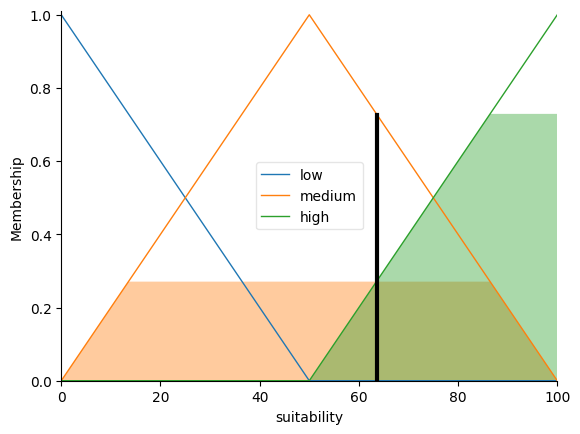

In [16]:
example_name='Adventure Lover'
first_rank,first_details=rank_destinations(example_name)
first_city=first_rank.iloc[0]['City']
print('Example scenario:',example_name,'— city:',first_city)
display(first_details[first_details['City']==first_city][['Theme','Name','compatibility','weight','status']])

# Quick diagnostics for the three controlled scenario comparisons.
for a,b in [('Adventure Lover','Adventurer Seeking Relaxation'),
            ('Adventure Lover','Adventure Preference Change'),
            ('Balanced Traveler','Budget-Constrained Traveler')]:
    a_rank,_=rank_destinations(a)
    b_rank,_=rank_destinations(b)
    merged=a_rank[['City','suitability_score']].merge(
        b_rank[['City','suitability_score']],on='City',suffixes=('_before','_after'))
    differences=(merged['suitability_score_after']-merged['suitability_score_before']).abs()
    print(f'{a} → {b}: max |Δ score| = {differences.max():.3f}'
          if differences.notna().any() else f'{a} → {b}: scores unavailable')

# Optional class-style visualization for a single simulated city:
row=first_rank.iloc[0]
if pd.notna(row['suitability_score']):
    sim=ctrl.ControlSystemSimulation(sillage_ctrl)
    for group in THEME_GROUPS:
        sim.input[group]=float(row[group+'_match'])
    sim.compute()
    suitability.view(sim=sim)
    plt.show()

### Sources used for this implementation

- `01_FuzzyControlSystem.ipynb` — `skfuzzy.control` workflow, variables, IF–THEN rules, control system and centroid defuzzification.
- `03_FuzzyVacationPlanner.ipynb` — separate personality and current-trip inputs, `trimf`, rule simulation and output visualization.
- `02_FuzzyClustering.ipynb` — illustrates fuzzy memberships, **not used** as the recommendation algorithm.
- `03_Sillage_devoir_tuto.ipynb` — illustrative traveler–destination compatibility before fuzzy inference.
- `Sillage_fuzzy_model_evaluation.ipynb` and `Cities.csv` — unchanged group profiles, seven scenarios, 19 topics and current dataset.

## 7. Technical Validation and Simulation

Seven synthetic scenarios are evaluated with the **50-destination European prototype CSV**, including its actual cost estimates, landscape flags and climate flags. PASS/FAIL applies only to narrowly specified technical checks. In particular, budget screening is tested under an **explicit illustrative seven-day conversion assumption** rather than a verified trip price.


### 7.1. Expected vs. Actual Results

We use all seven predefined scenarios. The **Expected** column is specified independently of the actual rankings. **Actual** reports top-ranked destinations, score ranges and coverage; it does not itself constitute a validation pass. A separate automated test table follows.

In [ ]:
# Run after the previous cells have created rankings_df, scenario_names and all model functions.
SCENARIO_EXPECTATIONS = {
    'Adventure Lover': 'Destinations offering more physical activities should fit this profile better, all else equal.',
    'Relaxation Lover': 'Destinations offering more relaxation should fit this profile better, all else equal.',
    'Food Explorer': 'Gastronomy is weighted more strongly than for the Balanced Traveler.',
    'Balanced Traveler': 'A mixed profile should produce finite, reproducible scores without a missing group.',
    'Adventurer Seeking Relaxation': 'Compared with Adventure Lover, current-trip relaxation preferences should change relevant compatibility scores.',
    'Budget-Constrained Traveler': 'Destinations above CHF 700 in the synthetic seven-day cost proxy must be excluded.',
    'Adventure Preference Change': 'Changing only trip activity from high to low should alter t24 compatibility.'
}

# Reuse the rankings already produced by the original notebook.
all_rankings_by_name = {name: rankings_df[rankings_df['Scenario'] == name].copy()
                        for name in scenario_names}
# Collect theme-level diagnostics for controlled comparisons.
all_diagnostics = {}
for name in scenario_names:
    _, details = rank_destinations(name)
    all_diagnostics[name] = details

result_rows = []
for name in scenario_names:
    df = all_rankings_by_name[name]
    valid = df[df['suitability_score'].notna()].sort_values('suitability_score', ascending=False)
    top = ', '.join(valid['City'].head(3).tolist()) if len(valid) else 'No scored cities'
    score_range = (f"{valid['suitability_score'].min():.1f}–{valid['suitability_score'].max():.1f}"
                   if len(valid) else 'N/A')
    result_rows.append({
        'Scenario': name,
        'Expected behavior': SCENARIO_EXPECTATIONS[name],
        'Actual: top 3': top,
        'Actual: score range': score_range,
        'Scored cities': len(valid),
        'Complete 19/19': int((df['themes_scored'].eq(19) & df['themes_partial'].eq('') &
                                df['budget_status'].ne('budget:unknown')).sum()),
        'Budget excluded': int(df['status'].eq('excluded_over_budget').sum())
    })
expected_actual = pd.DataFrame(result_rows)
display(expected_actual)


,Scenario,Expected behavior,Actual: top 3,Actual: score range,Scored cities,Complete 19/19,Budget excluded
0,Adventure Lover,Destinations offering more physical activities...,"Bergen, Brasov, Reykjavik",49.7–63.7,50,0,0
1,Relaxation Lover,Destinations offering more relaxation should f...,"Rome, Seville, Athens",50.2–55.5,50,0,0
2,Food Explorer,Gastronomy is weighted more strongly than for ...,"Edinburgh, Paris, Krakow",50.2–62.6,50,0,0
3,Balanced Traveler,"A mixed profile should produce finite, reprodu...","London, Dublin, Zurich",50.7–63.0,50,0,0
4,Adventurer Seeking Relaxation,"Compared with Adventure Lover, current-trip re...","Dublin, Lucerne, Salzburg",49.9–56.1,50,0,0
5,Budget-Constrained Traveler,Destinations above CHF 700 in the synthetic se...,"Krakow, Ljubljana, Maribor",53.4–55.5,5,0,45
6,Adventure Preference Change,Changing only trip activity from high to low s...,"Brussels, London, Bergen",49.7–55.0,50,0,0


### 7.2. Automated consistency tests (PASS / FAIL / INCONCLUSIVE)

The assertions are deliberately narrow. We check **theme-level responses** for the controlled one-variable modifications, not an unjustified requirement that every entire ranking must change in a predetermined direction. An equal final Mamdani score may conceal different intermediate matches. Budget enforcement cannot be asserted from the original destination dataset because it contains no comparable trip-level costs in CHF.

In [18]:
# Reusable diagnostics and validation helpers
EPS = 1e-8

def theme_scores(scenario, theme):
    diag = all_diagnostics[scenario]
    out = diag[diag['Theme'] == theme][['City', 'compatibility', 'weight', 'status']].copy()
    return out.drop_duplicates(subset=['City']).set_index('City')


def changed_theme(a, b, theme):
    x, y = theme_scores(a, theme), theme_scores(b, theme)
    df = x[['compatibility']].join(y[['compatibility']], how='inner',
                                    lsuffix='_before', rsuffix='_after')
    df['delta'] = df['compatibility_after'] - df['compatibility_before']
    return df


def add_test(rows, scenario, criterion, passed=None, evidence='', reason=''):
    status = 'INCONCLUSIVE' if passed is None else ('PASS' if bool(passed) else 'FAIL')
    rows.append({'Scenario': scenario, 'Test': criterion, 'Status': status,
                 'Evidence': evidence, 'Limitation': reason})

validation_rows = []

# Technical invariants common to every scenario
for name in scenario_names:
    r = all_rankings_by_name[name]
    finite = r['suitability_score'].dropna()
    add_test(validation_rows, name, 'Valid fuzzy output range 0–100',
             len(finite) > 0 and finite.between(0, 100).all(),
             f'{len(finite)}/{len(r)} scored; range '
             + (f'{finite.min():.2f}–{finite.max():.2f}' if len(finite) else 'N/A'))

# 1: A very active traveler should match high-activity cities better at theme t24.
a = theme_scores('Adventure Lover', 't24').join(cities_selected.set_index('City')[['t24']])
high = a.loc[a['t24'] >= 0.70, 'compatibility'].dropna()
low = a.loc[a['t24'] <= 0.30, 'compatibility'].dropna()
add_test(validation_rows, 'Adventure Lover', 'Higher t24 match for high-activity cities',
         float(high.mean()) > float(low.mean()) + EPS if len(high) and len(low) else None,
         f'mean high={high.mean():.3f}; mean low={low.mean():.3f}',
         'Requires cities on both ends of the activity scale' if not len(high) or not len(low) else '')

# 2: A relaxation-oriented traveler should match high-relaxation cities better at theme t4.
a = theme_scores('Relaxation Lover', 't4').join(cities_selected.set_index('City')[['t4']])
high = a.loc[a['t4'] >= 0.70, 'compatibility'].dropna()
low = a.loc[a['t4'] <= 0.30, 'compatibility'].dropna()
add_test(validation_rows, 'Relaxation Lover', 'Higher t4 match for high-relaxation cities',
         float(high.mean()) > float(low.mean()) + EPS if len(high) and len(low) else None,
         f'mean high={high.mean():.3f}; mean low={low.mean():.3f}',
         'Requires cities on both ends of the relaxation scale' if not len(high) or not len(low) else '')

# 3: Food interest must meaningfully affect the gastronomy weight.
fw = theme_scores('Food Explorer', 't2')['weight']
bw = theme_scores('Balanced Traveler', 't2')['weight']
common = fw.index.intersection(bw.index)
add_test(validation_rows, 'Food Explorer', 'Gastronomy weight exceeds Balanced Traveler',
         bool((fw.loc[common] > bw.loc[common] + EPS).all()) if len(common) else None,
         f'Food mean weight={fw.mean():.3f}, balanced={bw.mean():.3f}')

# 4: Recalculate one city, verifying deterministic inference at fixed inputs.
r, _ = rank_destinations('Balanced Traveler')
orig = all_rankings_by_name['Balanced Traveler'].set_index('City')['suitability_score']
again = r.set_index('City')['suitability_score'].reindex(orig.index)
valid = orig.notna() & again.notna()
repeat_delta = (orig[valid] - again[valid]).abs()
add_test(validation_rows, 'Balanced Traveler', 'Repeated inputs give the same score',
         bool((repeat_delta <= 1e-6).all()) if valid.any() else None,
         f'max |Δ|={repeat_delta.max():.8f}' if valid.any() else 'No comparable scores')

# 5: Trip preference modification must influence at least one relevant theme score.
changed = [changed_theme('Adventure Lover', 'Adventurer Seeking Relaxation', t)
           for t in ('t4', 't14', 't24')]
n_changed = [int((d['delta'].abs() > EPS).sum()) for d in changed]
add_test(validation_rows, 'Adventurer Seeking Relaxation',
         'Changing trip plans changes relevant theme matches',
         sum(n_changed) > 0,
         f'Cities with changed t4/t14/t24: {n_changed}')

# 6: Budget hard-cap verification against the *illustrative* seven-day CHF proxy.
# The dataset provides an estimated daily cost in EUR, NOT an actual trip price in CHF.
limited = all_rankings_by_name['Budget-Constrained Traveler']
base_costs = cities.set_index('City')['daily_cost_eur_estimate'].astype(float) * TRIP_DAYS * EUR_TO_CHF_ILLUSTRATIVE
costs = base_costs.reindex(limited['City']).to_numpy()
if np.isfinite(costs).all() and (costs > 700).any():
    over = limited.loc[costs > 700]
    excl = over['status'].eq('excluded_over_budget')
    add_test(validation_rows, 'Budget-Constrained Traveler',
             'Synthetic assumed trip costs above CHF 700 are excluded',
             bool(excl.all()), f'{int(excl.sum())}/{len(over)} excluded',
             'Only proves behavior under synthetic cost, 7-day and EUR-to-CHF assumptions')
else:
    add_test(validation_rows, 'Budget-Constrained Traveler',
             'Synthetic assumed trip costs above CHF 700 are excluded', None,
             'No usable over-budget cities',
             'Need complete cost proxy and at least one over-budget city')

# 7: One-variable change in trip t24 must change the t24 compatibility where measurable.
d = changed_theme('Adventure Lover', 'Adventure Preference Change', 't24')
add_test(validation_rows, 'Adventure Preference Change',
         'Changing only trip t24 affects t24 compatibility',
         bool((d['delta'].abs() > EPS).any()) if d['delta'].notna().any() else None,
         f"{int((d['delta'].abs() > EPS).sum())} / {int(d['delta'].notna().sum())} city matches changed")

# Display results; FAIL means observed test criterion did not hold; INCONCLUSIVE means insufficient data.
validation_df = pd.DataFrame(validation_rows)
display(validation_df)
print('Validation status counts:')
print(validation_df['Status'].value_counts().to_string())


,Scenario,Test,Status,Evidence,Limitation
0,Adventure Lover,Valid fuzzy output range 0–100,PASS,50/50 scored; range 49.74–63.71,
1,Relaxation Lover,Valid fuzzy output range 0–100,PASS,50/50 scored; range 50.21–55.52,
2,Food Explorer,Valid fuzzy output range 0–100,PASS,50/50 scored; range 50.19–62.56,
3,Balanced Traveler,Valid fuzzy output range 0–100,PASS,50/50 scored; range 50.69–62.95,
4,Adventurer Seeking Relaxation,Valid fuzzy output range 0–100,PASS,50/50 scored; range 49.90–56.14,
5,Budget-Constrained Traveler,Valid fuzzy output range 0–100,PASS,5/50 scored; range 53.42–55.45,
6,Adventure Preference Change,Valid fuzzy output range 0–100,PASS,50/50 scored; range 49.68–55.00,
7,Adventure Lover,Higher t24 match for high-activity cities,PASS,mean high=0.676; mean low=0.000,
8,Relaxation Lover,Higher t4 match for high-relaxation cities,INCONCLUSIVE,mean high=0.842; mean low=nan,Requires cities on both ends of the relaxation...
9,Food Explorer,Gastronomy weight exceeds Balanced Traveler,PASS,"Food mean weight=0.958, balanced=0.575",


Validation status counts:
Status
PASS            13
INCONCLUSIVE     1


### 7.3. Comparative figures

The first figure compares the best observed scores for each scenario. It is descriptive, **not** evidence that those destinations are correct. The second figure compares the **same destinations** under a controlled input change; the third summarizes test outcomes. These plots are computed from results, not manually entered numbers.

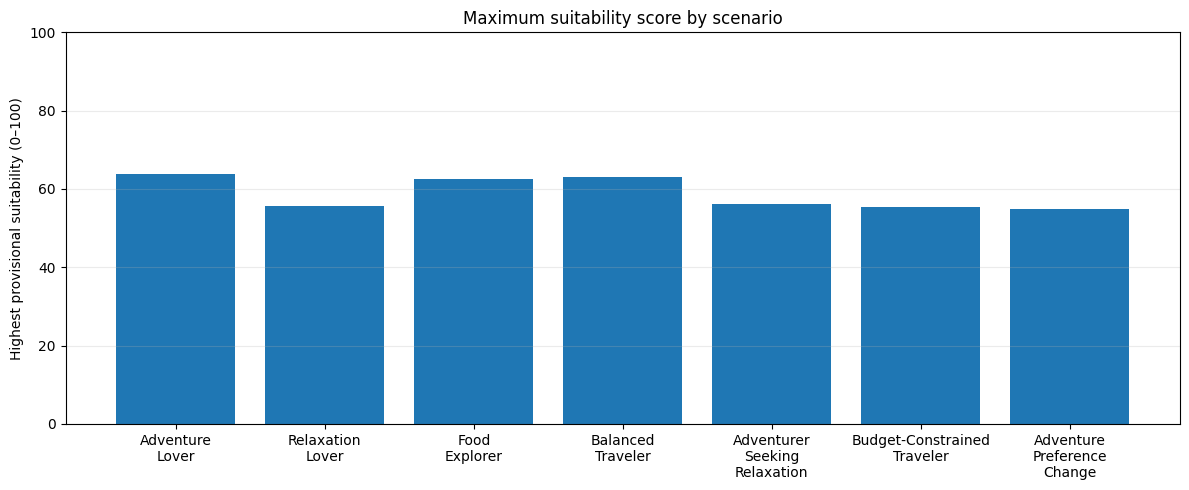

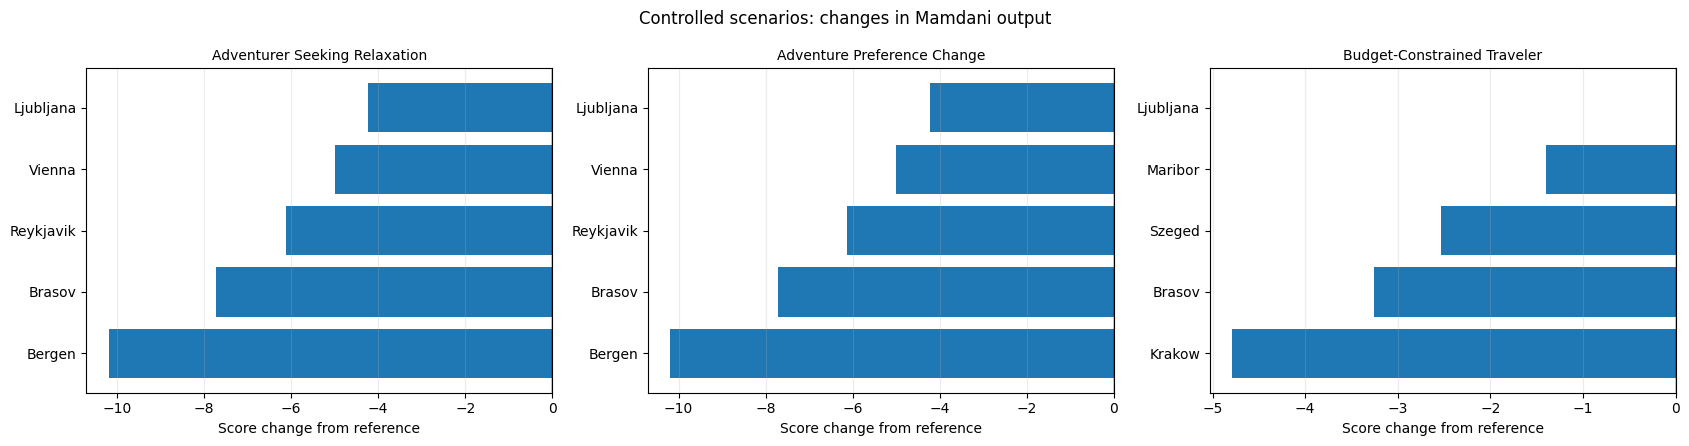

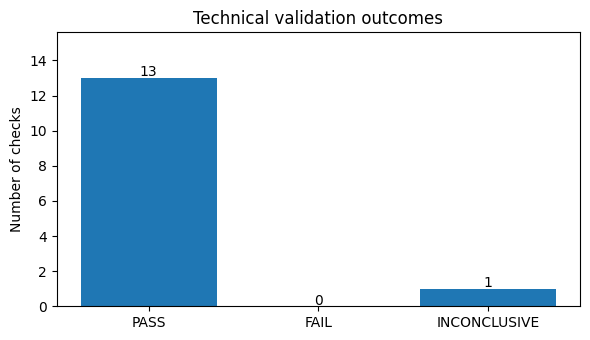

In [19]:
# Figure 1 — strongest scored destination for each scenario
fig, ax = plt.subplots(figsize=(12, 5))
plot = (rankings_df.groupby('Scenario', sort=False)['suitability_score']
        .max().reindex(scenario_names))
ax.bar(range(len(plot)), plot.values)
ax.set_xticks(range(len(plot)), [s.replace(' ', '\n') for s in plot.index], rotation=0)
ax.set_ylim(0, 100)
ax.set_ylabel('Highest provisional suitability (0–100)')
ax.set_title('Maximum suitability score by scenario')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

# Figure 2 — compare the same destinations before and after a controlled preference change
pairs = [
    ('Adventure Lover', 'Adventurer Seeking Relaxation'),
    ('Adventure Lover', 'Adventure Preference Change'),
    ('Balanced Traveler', 'Budget-Constrained Traveler')
]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (before, after) in zip(axes, pairs):
    a = all_rankings_by_name[before].set_index('City')['suitability_score']
    b = all_rankings_by_name[after].set_index('City')['suitability_score']
    common = a.index.intersection(b.index)
    delta = (b.loc[common] - a.loc[common]).dropna().sort_values()
    if len(delta):
        # Top five cities with largest absolute changes, kept in sorted display order
        shown = delta.loc[delta.abs().nlargest(min(5, len(delta))).index].sort_values()
        ax.barh(shown.index, shown.values)
    else:
        ax.text(0.5, 0.5, 'No comparable scores', transform=ax.transAxes,
                ha='center', va='center')
    ax.axvline(0, linewidth=1, color='black')
    ax.set_title(after, fontsize=10)
    ax.set_xlabel('Score change from reference')
    ax.grid(axis='x', alpha=0.25)
plt.suptitle('Controlled scenarios: changes in Mamdani output')
plt.tight_layout()
plt.show()

# Figure 3 — validation outcomes, including explicitly inconclusive tests
counts = validation_df['Status'].value_counts().reindex(
    ['PASS', 'FAIL', 'INCONCLUSIVE'], fill_value=0)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(counts.index, counts.values)
ax.set_ylabel('Number of checks')
ax.set_title('Technical validation outcomes')
for i, val in enumerate(counts.values):
    ax.text(i, val + 0.1, str(val), ha='center')
ax.set_ylim(0, max(counts.max() * 1.2, 1))
plt.tight_layout()
plt.show()


## 8. Results and Discussion

The interpretations below are generated from the observed tests. **PASS** means the narrow test condition was satisfied; it does not establish that the real-world destination recommendation is correct. **FAIL** exposes a mismatch with a predeclared expectation. **INCONCLUSIVE** means the dataset cannot establish the claim. The 19 themes are represented in the questionnaire mapping, but some cannot be fully evaluated without real categorical and budget information.

In [20]:
# Generated discussion based on actual validation outcomes
counts = validation_df['Status'].value_counts()
passed = int(counts.get('PASS', 0))
failed = int(counts.get('FAIL', 0))
inconclusive = int(counts.get('INCONCLUSIVE', 0))

print('RESULTS AND DISCUSSION')
print(f'The automated checks returned {passed} PASS, {failed} FAIL, '
      f'and {inconclusive} INCONCLUSIVE results.')
print(f'The model generated provisional destination scores for '
      f"{rankings_df['Scenario'].nunique()} synthetic scenarios. "
      'The synthetic European dataset does not establish actual destination suitability.')

print('\nSUPPORTED FINDINGS:')
for _, item in validation_df[validation_df['Status'] == 'PASS'].iterrows():
    print(f"- {item['Scenario']}: {item['Test']} ({item['Evidence']}).")

print('\nFAILED CHECKS:')
for _, item in validation_df[validation_df['Status'] == 'FAIL'].iterrows():
    print(f"- {item['Scenario']}: {item['Test']} ({item['Evidence']}).")
if not failed:
    print('- None of the defined checks failed; this does not prove general validity.')

print('\nUNVERIFIABLE CLAIMS:')
for _, item in validation_df[validation_df['Status'] == 'INCONCLUSIVE'].iterrows():
    print(f"- {item['Scenario']}: {item['Test']} — {item['Limitation']}.")
if not inconclusive:
    print('- None in the currently implemented checks.')

print('\nLIMITATIONS AND NEXT IMPROVEMENTS:')
print('- City theme scores are synthetic, not validated travel facts.')
print('- Landscape and climate flags are available, but other categorical travel answers lack exact destination counterparts.')
print('- Budget uses a synthetic daily EUR cost multiplied by an assumed seven days and illustrative FX factor 1.0.')
print('- Trip duration, party size, dates and live quotes are not modeled; this is not real budget feasibility.')
print('- Some themes cannot be observed; consult themes_missing and themes_partial.')
print('- The three aggregated dimensions, weights and 27 IF–THEN rules are design assumptions.')
print('- Add real data for unmatched questionnaire themes and verified costs matched to party/dates/duration,')
print('  a larger set of controlled perturbation tests and user evaluation.')


RESULTS AND DISCUSSION
The automated checks returned 13 PASS, 0 FAIL, and 1 INCONCLUSIVE results.
The model generated provisional destination scores for 7 synthetic scenarios. The synthetic European dataset does not establish actual destination suitability.

SUPPORTED FINDINGS:
- Adventure Lover: Valid fuzzy output range 0–100 (50/50 scored; range 49.74–63.71).
- Relaxation Lover: Valid fuzzy output range 0–100 (50/50 scored; range 50.21–55.52).
- Food Explorer: Valid fuzzy output range 0–100 (50/50 scored; range 50.19–62.56).
- Balanced Traveler: Valid fuzzy output range 0–100 (50/50 scored; range 50.69–62.95).
- Adventurer Seeking Relaxation: Valid fuzzy output range 0–100 (50/50 scored; range 49.90–56.14).
- Budget-Constrained Traveler: Valid fuzzy output range 0–100 (5/50 scored; range 53.42–55.45).
- Adventure Preference Change: Valid fuzzy output range 0–100 (50/50 scored; range 49.68–55.00).
- Adventure Lover: Higher t24 match for high-activity cities (mean high=0.676; mean low=

### Results and Discussion

We tested our fuzzy recommendation system using seven different traveler scenarios and 50 European destinations.

Overall, 13 tests passed, none failed, and one was inconclusive. The model produced scores between 0 and 100 and gave different recommendations depending on the travelers' preferences.

The budget test also worked under our synthetic cost assumptions, excluding 45 destinations that exceeded the maximum budget.

However, we noticed some limitations. The relaxation test was inconclusive because there were not enough low-relaxation destinations to make a comparison. Also, none of the destinations had complete information for all 19 themes.

Another observation is that the suitability scores stayed relatively close to each other, mostly between 50 and 65. This could limit how well the model distinguishes different destinations.

These results show that our fuzzy system behaves consistently in several situations, but more testing and better destination data are needed before we can consider the recommendations fully reliable.

### 8.1. Summary for the report (complete after executing)

**Method.** We evaluated our 27-rule Mamdani fuzzy recommendation system on seven synthetic traveler scenarios, using 50 European destinations from a synthetic prototype CSV. We mapped 19 questionnaire themes to the attributes that the dataset actually supports. We used explicit assumptions for an illustrative seven-day budget proxy.

**Results.** Fill in the PASS, FAIL and INCONCLUSIVE counts from the automatically generated table. Report at least one relevant score comparison and one observed limitation. A PASS on an input-response test does not prove that a real destination is suitable.

**Limitations.** Destination scores are synthetic. Change of scenery cannot be assessed without the origin, and several categorical questions lack full matching attributes. Trip cost is estimated from assumed duration and an illustrative conversion factor, not verified for party size or season.

**Next steps.** Test real destination data, season-specific climate, verified prices and richer category matches; include additional perturbation and user testing.
